Guide:
YRS = years played
G = games played
AB = at bats
R = runs
H = hits
2B = doubles
3B = triples
HR = home runs
RBI = rbis?
BB = walks
SO = strike outs
SB = stolen bases
CS = caught stealing
BA = batting average
HOF = hall of fame (yes or no)

In [1]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

In [2]:
df = pd.read_csv('500hits.csv', encoding='latin-1')
df

,PLAYER,YRS,G,AB,R,H,2B,3B,HR,RBI,BB,SO,SB,CS,BA,HOF
0,Ty Cobb,24,3035,11434,2246,4189,724,295,117,726,1249,357,892,178,0.366,1
1,Stan Musial,22,3026,10972,1949,3630,725,177,475,1951,1599,696,78,31,0.331,1
2,Tris Speaker,22,2789,10195,1882,3514,792,222,117,724,1381,220,432,129,0.345,1
3,Derek Jeter,20,2747,11195,1923,3465,544,66,260,1311,1082,1840,358,97,0.310,1
4,Honus Wagner,21,2792,10430,1736,3430,640,252,101,0,963,327,722,15,0.329,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
460,Jim Wynn,15,1920,6653,1105,1665,285,39,291,964,1224,1427,225,101,0.250,0
461,Jorge Posada,17,1829,6092,900,1664,379,10,275,1065,936,1453,20,21,0.273,0
462,Brady Anderson,15,1834,6499,1062,1661,338,67,210,761,960,1190,315,100,0.256,0
463,Cookie Rojas,16,1822,6309,714,1660,254,25,54,593,396,489,74,68,0.263,0


In [3]:
df = df.drop(columns=['PLAYER', 'CS'])
df

,YRS,G,AB,R,H,2B,3B,HR,RBI,BB,SO,SB,BA,HOF
0,24,3035,11434,2246,4189,724,295,117,726,1249,357,892,0.366,1
1,22,3026,10972,1949,3630,725,177,475,1951,1599,696,78,0.331,1
2,22,2789,10195,1882,3514,792,222,117,724,1381,220,432,0.345,1
3,20,2747,11195,1923,3465,544,66,260,1311,1082,1840,358,0.310,1
4,21,2792,10430,1736,3430,640,252,101,0,963,327,722,0.329,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
460,15,1920,6653,1105,1665,285,39,291,964,1224,1427,225,0.250,0
461,17,1829,6092,900,1664,379,10,275,1065,936,1453,20,0.273,0
462,15,1834,6499,1062,1661,338,67,210,761,960,1190,315,0.256,0
463,16,1822,6309,714,1660,254,25,54,593,396,489,74,0.263,0


In [4]:
x = df.iloc[:,0:13]
y = df.iloc[:,13]
print(x)
print(y)

     YRS     G     AB     R     H   2B   3B   HR   RBI    BB    SO   SB     BA
0     24  3035  11434  2246  4189  724  295  117   726  1249   357  892  0.366
1     22  3026  10972  1949  3630  725  177  475  1951  1599   696   78  0.331
2     22  2789  10195  1882  3514  792  222  117   724  1381   220  432  0.345
3     20  2747  11195  1923  3465  544   66  260  1311  1082  1840  358  0.310
4     21  2792  10430  1736  3430  640  252  101     0   963   327  722  0.329
..   ...   ...    ...   ...   ...  ...  ...  ...   ...   ...   ...  ...    ...
460   15  1920   6653  1105  1665  285   39  291   964  1224  1427  225  0.250
461   17  1829   6092   900  1664  379   10  275  1065   936  1453   20  0.273
462   15  1834   6499  1062  1661  338   67  210   761   960  1190  315  0.256
463   16  1822   6309   714  1660  254   25   54   593   396   489   74  0.263
464   15  1468   5629   785  1660  247   71   61   499   266   471  267  0.295

[465 rows x 13 columns]
0      1
1      1
2      1


In [5]:
x_train, x_test, y_train, y_test = train_test_split(x, y, random_state=11, test_size=0.2)

In [6]:
scaler = MinMaxScaler(feature_range=(0,1))

In [7]:
x_train = scaler.fit_transform(x_train)
x_test = scaler.fit_transform(x_test)
print(x_train)
print(x_test)

[[0.46666667 0.35255438 0.31382907 ... 0.67820248 0.00929235 0.225     ]
 [0.13333333 0.25543753 0.24989842 ... 0.18595041 0.17155111 0.38333333]
 [0.2        0.23672231 0.18854124 ... 0.32386364 0.02144389 0.375     ]
 ...
 [0.46666667 0.32169954 0.32263308 ... 0.13429752 0.18656183 0.64166667]
 [0.53333333 0.58523015 0.50684004 ... 0.61260331 0.22444603 0.175     ]
 [0.2        0.21041983 0.16402546 ... 0.41219008 0.02144389 0.3       ]]
[[0.5        0.33425224 0.10288675 ... 0.10147173 0.02853261 0.35869565]
 [0.5        0.44727774 0.30662472 ... 0.38652208 0.06929348 0.32608696]
 [0.28571429 0.452102   0.51720947 ... 0.12083656 0.4986413  1.        ]
 ...
 [0.42857143 0.31219848 0.15173945 ... 0.17893106 0.04076087 0.40217391]
 [0.35714286 0.47553411 0.50943745 ... 0.54531371 0.06793478 0.54347826]
 [0.57142857 0.69676085 0.67246484 ... 0.21068939 0.26766304 0.75      ]]


In [8]:
knn = KNeighborsClassifier(n_neighbors=7)
knn.fit(x_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",7
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [9]:
y_pred = knn.predict(x_test)
y_pred

array([0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0,
       0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0,
       1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0,
       0, 0, 0, 1, 1])

In [10]:
knn.score(x_test,y_test)

0.7956989247311828

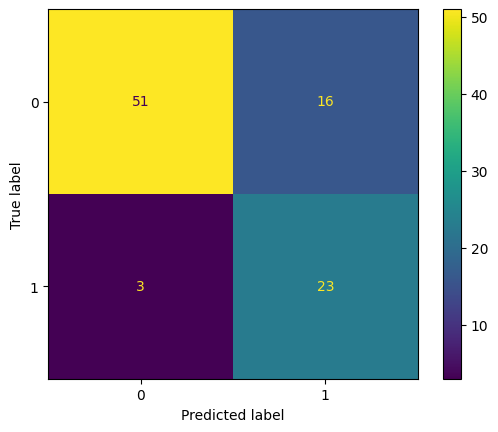

In [11]:
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot()

In [20]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.93      0.82      0.87        67
           1       0.65      0.85      0.73        26

    accuracy                           0.83        93
   macro avg       0.79      0.83      0.80        93
weighted avg       0.85      0.83      0.83        93

